# Lottery Economics — analysis notebook

Walks through the same computations the website shows, using the `lottery` package. Re-run after `python -m lottery.ingest` to fill in the real-data sections.

**Nothing here predicts numbers.** The point is the opposite: to show that apparent patterns are what fair randomness looks like.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # run from notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lottery import rules, stats, config
from lottery import math as lm
pd.set_option('display.width', 120)
data = {g: stats.load_draws(g) for g in rules.GAMES}
{g: (None if d is None else len(d)) for g, d in data.items()}

{'powerball': None,
 'mega_millions': None,
 'ny_numbers': None,
 'win4': None,
 'ny_lotto': None,
 'take5': None,
 'pick10': None,
 'quick_draw': None,
 'cash4life': None,
 'millionaire_for_life': None}

## 1. Exact odds
Each tier's probability by counting combinations; compare with the published odds.

In [2]:
rows = []
for g in ('powerball', 'mega_millions'):
    era = rules.current_era(g)
    for r in lm.odds_table(era):
        rows.append({'game': era.label, 'match': f"{r['white']}+{r['special']}", 'prize': r['prize'],
                     '1 in (exact)': round(r['one_in'], 2), '1 in (official)': r['official_one_in']})
pd.DataFrame(rows)

,game,match,prize,1 in (exact),1 in (official)
0,Powerball 5/69 + 1/26 ($2),5+1,JACKPOT,2.922013e+08,2.922013e+08
1,Powerball 5/69 + 1/26 ($2),5+0,1000000,1.168805e+07,1.168805e+07
2,Powerball 5/69 + 1/26 ($2),4+1,50000,9.131292e+05,9.131292e+05
3,Powerball 5/69 + 1/26 ($2),4+0,100,3.652517e+04,3.652517e+04
4,Powerball 5/69 + 1/26 ($2),3+1,100,1.449411e+04,1.449411e+04
5,Powerball 5/69 + 1/26 ($2),3+0,7,5.797600e+02,5.797600e+02
6,Powerball 5/69 + 1/26 ($2),2+1,7,7.013300e+02,7.013300e+02
7,Powerball 5/69 + 1/26 ($2),1+1,4,9.198000e+01,9.198000e+01
8,Powerball 5/69 + 1/26 ($2),0+1,4,3.832000e+01,3.832000e+01
9,Mega Millions 5/70 + 1/24 ($5),5+1,JACKPOT,2.904723e+08,2.904723e+08


## 2. Expected value per $1
From the advertised number down to what a NYC resident actually expects back.

In [3]:
rows = []
for g in ('powerball', 'mega_millions'):
    era = rules.current_era(g)
    for J, N in [(era.starting_jackpot, 10e6), (1e9, 200e6)]:
        ev = lm.ev_breakdown(era, J, tickets_sold=N)
        rows.append({'game': era.label, 'jackpot': f'${J/1e6:,.0f}M', 'tickets (assumed)': f'{N/1e6:.0f}M',
                     **{s: round(ev[s]['total_per_dollar'], 3) for s in ('advertised', 'cash', 'after_tax', 'with_split')}})
pd.DataFrame(rows)

,game,jackpot,tickets (assumed),advertised,cash,after_tax,with_split
0,Powerball 5/69 + 1/26 ($2),$20M,10M,0.194,0.174,0.084,0.084
1,Powerball 5/69 + 1/26 ($2),"$1,000M",200M,1.871,0.880,0.425,0.329
2,Mega Millions 5/70 + 1/24 ($5),$50M,10M,0.258,0.238,0.115,0.115
3,Mega Millions 5/70 + 1/24 ($5),"$1,000M",200M,0.912,0.520,0.251,0.211


## 2b. Every New York game
EV per $1 before tax, after tax owed, and after withholding only. Values flagged `verified=False` use prize amounts not confirmed from an official page.

In [4]:
rows = []
for g in rules.GAMES:
    if g in ('powerball', 'mega_millions'):
        continue
    era = rules.current_era(g)
    for owed, wh in zip(lm.game_ev(era, 'owed'), lm.game_ev(era, 'withholding')):
        rows.append({'game': rules.GAME_LABELS[g], 'play': owed['play'], 'pre_tax': round(owed['pre_tax'], 3),
                     'after_tax_owed': round(owed['after_tax'], 3), 'after_withholding': round(wh['after_tax'], 3),
                     'verified': owed['verified']})
pd.DataFrame(rows)

,game,play,pre_tax,after_tax_owed,after_withholding,verified
0,NY Numbers,straight,0.500,0.241,0.500,True
1,NY Numbers,box_3way,0.480,0.231,0.480,True
2,NY Numbers,box_6way,0.480,0.231,0.480,True
3,Win 4,straight,0.500,0.241,0.500,False
4,Win 4,box_24way,0.480,0.231,0.480,False
5,Win 4,box_12way,0.480,0.231,0.480,False
6,Win 4,box_6way,0.480,0.231,0.480,False
7,Win 4,box_4way,0.480,0.231,0.480,False
8,NY Lotto,pari-mutuel,0.400,0.193,0.272,True
9,Take 5,pari-mutuel,0.500,0.241,0.461,True


## 3. Why the chi-square needs a correction
A draw takes 5 *distinct* balls, so counts are negatively correlated and the plain Pearson statistic averages m−k instead of m−1. Multiplying by (m−1)/(m−k) fixes it.

In [5]:
rng = np.random.default_rng(0)
m, k, n = 69, 5, 500
raw = np.array([stats.chi_square(stats.simulate_counts(n, k, m, rng), n, k, m)['statistic_raw'] for _ in range(3000)])
print(f'mean raw X^2 = {raw.mean():.1f}  (theory m-k = {m-k})')
print(f'mean corrected = {(raw*(m-1)/(m-k)).mean():.1f}  (theory m-1 = {m-1})')

mean raw X^2 = 63.9  (theory m-k = 64)
mean corrected = 67.9  (theory m-1 = 68)


## 4. Fair data has hot and cold numbers too
1,000 perfectly fair Powerball draws, generated by a seeded RNG.

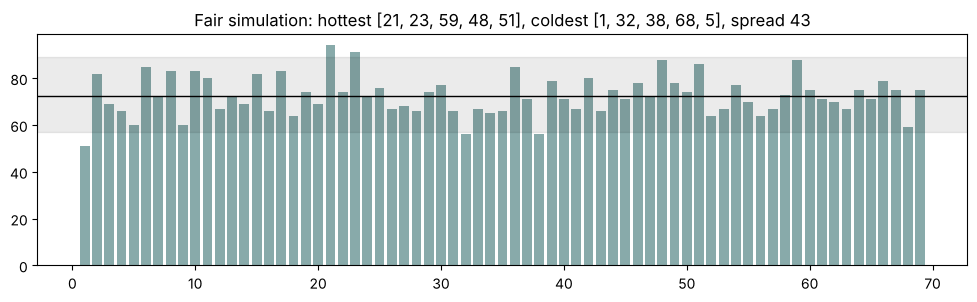

spread (max-min) over 1,000 fair histories: 5th pct 31.0 median 39.0 95th 48.0
share of fair histories with chi-square p < 0.05: 0.052
mean first-half vs second-half rank correlation: 0.0035


In [6]:
sim = stats.simulate_fair(rules.current_era('powerball'), 1000, histories=1000)
ex = sim['example']
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(ex['labels'], ex['counts'], color='#8aa')
ax.axhline(sim['expected'], color='k', lw=1)
ax.axhspan(*sim['band95'], color='k', alpha=.08)
ax.set_title(f"Fair simulation: hottest {ex['hot']}, coldest {ex['cold']}, spread {ex['spread']}")
plt.show()
print('spread (max-min) over 1,000 fair histories: 5th pct', sim['spread']['p05'], 'median', sim['spread']['median'], '95th', sim['spread']['p95'])
print('share of fair histories with chi-square p < 0.05:', sim['p_values']['share_below_005'])
print('mean first-half vs second-half rank correlation:', round(sim['persistence']['mean'], 4))

## 5. Real draws: frequencies and chi-square (per era, never pooled)

In [7]:
res = stats.analyze()
if not res['tests']:
    print('No data in data/ yet. Run: python -m lottery.ingest')
else:
    cols = ['game', 'era_label', 'ball_set', 'n_draws', 'statistic', 'df', 'p_value', 'p_bonferroni', 'significant']
    display(pd.DataFrame(res['tests'])[cols])

No data in data/ yet. Run: python -m lottery.ingest


In [8]:
for f in res['frequencies']:
    if f['ball_set'] not in ('white', 'special') or f['era_id'] not in ('pb_2015', 'mm_2025'):
        continue
    fig, ax = plt.subplots(figsize=(12, 2.5))
    ax.bar(f['labels'], f['counts'], color='#a88')
    ax.axhline(f['expected'], color='k', lw=1); ax.axhspan(*f['band95'], color='k', alpha=.08)
    ax.set_title(f"{f['era_label']} — {f['ball_set']} ({f['n_draws']} draws); outside 95% band: {f['outside_band']} (expect ~{f['expected_outside']})")
    plt.show()

## 6. Real data vs. fair simulation

In [9]:
for s in stats.simulation_report(histories=500):
    if s['real']:
        r = s['real']
        print(f"{s['era_label']}: spread {r['spread']} is at the {r['spread_percentile']:.0f}th percentile of fair data; "
              f"half-to-half correlation {r['persistence']:.3f} (fair 90% range {r['fair_persistence_p05_p95']})")
    else:
        print(f"{s['era_label']}: no real data yet")

Powerball 5/69 + 1/26 ($2): no real data yet
Mega Millions 5/70 + 1/24 ($5): no real data yet
